Import the libraries used to load data, build the model, and evaluate predictions.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense , Flatten
from sklearn.metrics import accuracy_score


Load the MNIST training and test sets and inspect their dimensions.

In [30]:
import tensorflow as tf

(X_train, Y_train), (X_test, Y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print(X_train.shape)  # (60000, 28, 28)
print(X_test.shape)   # (10000, 28, 28)

(60000, 28, 28)
(10000, 28, 28)


Check the dimensions of the first training image.

In [31]:
X_train[0].shape

(28, 28)

Display the pixel values of the first training image.

In [32]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

Scale image pixels to the 0-to-1 range for model training.

In [33]:
#i have to make all the values in the range of 0 to 1 because neural networks
#learns best in similar ranges
X_train = X_train/255
X_test = X_test/255

Create a neural network that maps flattened images to digit probabilities.

In [34]:
#here we are creating out neural network
model = Sequential([
    Input(shape = (28 , 28)),
    Flatten(),
    Dense(128 , activation = "relu"),#hidden layer
    Dense(10 , activation = "softmax")#output layer
])

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Configure the model's loss function and optimizer.

In [35]:
#we have to compile the model to tell how it should learn
#and how it should update its weight
model.compile(loss = "sparse_categorical_crossentropy" , optimizer = "Adam")

Train the network for 10 epochs with a validation split.

In [36]:
#epochs means revolving this data multiple times
model.fit(X_train , Y_train, epochs=10 , validation_split = 0.2)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.2875 - val_loss: 0.1520
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1295 - val_loss: 0.1217
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0880 - val_loss: 0.0977
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0654 - val_loss: 0.0948
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0500 - val_loss: 0.0904
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0387 - val_loss: 0.0862
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0299 - val_loss: 0.0944
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0248 - val_loss: 0.0949
Epoch 9/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0191 - val_loss: 0.0916
Epoch 10/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0162 - val_loss: 0.0972


Predict class probabilities for all test images.

In [37]:
#this will the probability for every number
Y_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 691us/step


Select the most probable digit for each test image.

In [38]:
#i am storing the number with maximum probability
Y_pred = Y_prob.argmax(axis = 1)

Calculate the model's classification accuracy on the test set.

In [39]:
print("the accuracy is:" , accuracy_score(Y_test , Y_pred) * 100)

the accuracy is: 97.76


Plot one example image from the test set.

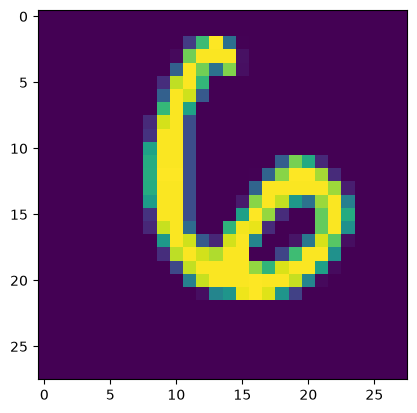

In [44]:
#i am plotting a random number from test set
plt.imshow(X_test[88])

Predict the digit shown in the selected test image.

In [46]:
outcome = model.predict(X_test[88].reshape(1,28,28))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


Display the predicted digit for the selected test image.

In [48]:
#it will prob of all numbers
print(outcome.argmax(axis = 1))

[6]
